# Laboratorul 1 — Python în biroul inteligent
**Sisteme bazate pe cunoștințe · Exemple rezolvate (citiți, rulați, modificați)**

Pe parcursul cursului studiem un *birou inteligent*: senzorii măsoară în fiecare minut temperatura, umiditatea, CO₂ și ocupanța. În acest laborator învățați Python-ul de care aveți nevoie **construind unelte care procesează aceste măsurători ale senzorilor**. Fiecare secțiune are același ritm:

1. 💡 **Idee** – o explicație scurtă
2. 🔧 **Exemplu rezolvat** – cod pe care îl rulați și îl citiți linie cu linie
3. 🎯 **Încercați** – o modificare de 1 minut pe care o faceți voi

După acest notebook, deschideți `Lab1_Exercitii.ipynb` – acolo scrieți *voi* codul.

**Cum îl folosiți:** rulați celulele de sus în jos (`Shift+Enter`). Celulele folosesc aceeași memorie, deci ordinea contează. Dacă ceva se strică, folosiți *Kernel → Restart & Run All*.

## 0. Este mediul vostru pregătit?
Puteți lucra **local** (Python + Jupyter, de preferat într-un mediu virtual), în **VS Code** sau în cloud (**Google Colab**, fără instalare). Celula de mai jos verifică versiunea de Python. Se recomandă Python 3.10 sau mai nou (versiunea stabilă curentă: 3.14).

> **Mediu virtual (instalări locale):**  `python -m venv .venv` → activați-l (`.venv\\Scripts\\activate` pe Windows, `source .venv/bin/activate` pe Linux/Mac) → `pip install notebook numpy pandas matplotlib seaborn scikit-learn`
> Într-un notebook, instalați cu `%pip install <pachet>` (nu cu `!pip`), ca pachetul să ajungă în *același* mediu cu kernelul care rulează.

In [1]:
import sys, platform
print("Python", sys.version.split()[0], "pe", platform.system())
assert sys.version_info >= (3, 9), "Instalați o versiune mai nouă de Python (se recomandă 3.10+)"
print("OK - mediul este pregătit")

Python 3.13.15 pe Linux
OK - mediul este pregătit


## 1. Obiecte, tipuri și variabile
💡 În Python **totul este un obiect**, iar o variabilă este doar un *nume* atașat unui obiect. Nu declarați niciodată un tip; Python îl deduce (*tipare dinamică*), dar refuză totuși operațiile fără sens (*tipare puternică*).

Regulă practică de denumire (PEP 8): `litere_mici_cu_underscore`.

In [2]:
# o măsurătoare de la un senzor din biroul inteligent
temperature = 21.4        # float  (°C)
occupancy   = 7           # int    (persoane în cameră)
room        = "Lab-204"   # str
window_open = False       # bool

for value in (temperature, occupancy, room, window_open):
    print(f"{value!r:>10}  ->  {type(value).__name__}")

      21.4  ->  float
         7  ->  int
 'Lab-204'  ->  str
     False  ->  bool


In [3]:
# Python are tipare dinamică: același nume poate indica alt obiect...
x = 5
x = "cinci"
print(type(x))

# ...dar are tipare puternică: operațiile fără sens produc o eroare
try:
    print(temperature + room)
except TypeError as err:
    print("TypeError:", err)

<class 'str'>
TypeError: unsupported operand type(s) for +: 'float' and 'str'


🎯 **Încercați:** adăugați o variabilă `co2_ppm = 640` și afișați-i tipul. Apoi încercați `int("12") + 1` și `str(12) + "1"` – care este diferența?

## 2. Operatori
💡 Aritmetici (`+ - * / // % **`), de comparare (`== != < <= > >=`), logici (`and or not`) și de atribuire (`= += -= ...`). Comparațiile returnează `True`/`False`. Precedența se poate schimba cu paranteze.

In [4]:
t_c = 21.4
t_f = t_c * 9/5 + 32          # Celsius -> Fahrenheit
print(f"{t_c} °C = {t_f:.1f} °F")

print(7 / 2, 7 // 2, 7 % 2, 2 ** 10)      # împărțire reală, împărțire cu rotunjire în jos, rest, putere

co2 = 1180
too_high   = co2 > 1000                    # comparare -> bool
comfortable = 20 <= t_c <= 24              # comparare înlănțuită (foarte pythonic)
print("CO2 prea mare:", too_high, "| temperatură confortabilă:", comfortable)
print("Deschideți fereastra:", too_high and not comfortable)   # operatori logici

21.4 °C = 70.5 °F
3.5 3 1 1024
CO2 prea mare: True | temperatură confortabilă: True
Deschideți fereastra: False


**Rețineți:** ultima expresie dintr-o celulă este afișată automat; `print()` este necesar pentru orice altceva. Un punct și virgulă `;` la final ascunde afișarea automată.

**Surpriza numerelor în virgulă mobilă** – o întrebare clasică de examen, relevantă și pentru datele de la senzori:

In [5]:
print(0.1 + 0.2)                  # 0.30000000000000004  (virgulă mobilă binară)
print(0.1 + 0.2 == 0.3)           # False!
import math
print(math.isclose(0.1 + 0.2, 0.3))   # True  -> comparați numerele float cu isclose, niciodată cu ==

0.30000000000000004
False
True


## 3. Containere: `list`, `tuple`, `set`, `dict`
💡 Un container grupează obiecte.

| tip | exemplu | ordonat | mutabil | duplicate | utilizare tipică |
|---|---|---|---|---|---|
| `list` (listă) | `[21.4, 21.6]` | da | da | da | o serie de măsurători |
| `tuple` (tuplă) | `(45.46, 24.05)` | da | **nu** | da | înregistrare fixă, ex. coordonate |
| `set` (mulțime) | `{"A","B"}` | nu | da | **nu** | elemente unice, teste de apartenență |
| `dict` (dicționar) | `{"temp": 21.4}` | da (din Python 3.7: ordinea inserării) | da | cheile sunt unice | câmpuri denumite, tabele de căutare |

> ℹ️ Suportul de curs mai vechi spune că dicționarele nu sunt ordonate. Era adevărat până la Python 3.5; **începând cu Python 3.7, un `dict` păstrează ordinea inserării**.

In [6]:
temps = [19.1, 19.0, 19.4, 20.2, 21.7, 22.5, 23.1, 22.8]     # o măsurătoare la fiecare 10 minute
print("primul:", temps[0], "| ultimul:", temps[-1])
print("secțiunea [2:5]:", temps[2:5])        # start inclus, stop exclus
print("din 2 în 2     :", temps[::2])
print("inversat       :", temps[::-1])

temps.append(22.1)                            # listele sunt mutabile
print(len(temps), min(temps), max(temps), round(sum(temps)/len(temps), 2))

location = (46.77, 23.60)                     # tuplă: înregistrare fixă
# location[0] = 0  -> TypeError (tuplele sunt imutabile)

rooms = {"Lab-204", "Lab-205", "Lab-204"}     # mulțimea elimină duplicatele
print(rooms, "Lab-205" in rooms)

sensor = {"id": "S-17", "type": "CO2", "unit": "ppm", "room": "Lab-204"}
print(sensor["type"], sensor.get("battery", "necunoscut"))   # .get evită KeyError
sensor["battery"] = 87
print(list(sensor.items())[:2])

primul: 19.1 | ultimul: 22.8
secțiunea [2:5]: [19.4, 20.2, 21.7]
din 2 în 2     : [19.1, 19.4, 21.7, 23.1]
inversat       : [22.8, 23.1, 22.5, 21.7, 20.2, 19.4, 19.0, 19.1]
9 19.0 23.1 21.1
{'Lab-204', 'Lab-205'} True
CO2 necunoscut
[('id', 'S-17'), ('type', 'CO2')]


**Comprehensiunile** (list comprehensions) construiesc un container nou dintr-unul vechi pe o singură linie lizibilă – le veți folosi constant cu datele:

In [7]:
temps_f   = [round(t * 9/5 + 32, 1) for t in temps]            # transformare
warm      = [t for t in temps if t > 21]                        # filtrare
labels    = {t: ("cald" if t > 21 else "ok") for t in temps[:4]}  # comprehensiune de dicționar
print(temps_f[:3]); print(warm); print(labels)

# enumerate și zip: buclă cu index / buclă peste două liste simultan
for i, (t, h) in enumerate(zip(temps[:3], [47.8, 47.9, 48.1])):
    print(f"măsurătoarea {i}: {t} °C, {h} %")

[66.4, 66.2, 66.9]
[21.7, 22.5, 23.1, 22.8, 22.1]
{19.1: 'ok', 19.0: 'ok', 19.4: 'ok', 20.2: 'ok'}
măsurătoarea 0: 19.1 °C, 47.8 %
măsurătoarea 1: 19.0 °C, 47.9 %
măsurătoarea 2: 19.4 °C, 48.1 %


🎯 **Încercați:** creați `cold = [t for t in temps if t < 19.5]`. Câte măsurători conține? Apoi folosiți o secționare (slicing) pentru a obține *ultimele trei* măsurători.

## 4. Șiruri de caractere și formatare (folosiți f-string)
💡 Șirurile sunt secvențe imutabile de caractere. Modul modern de a formata ieșirea este **f-string**; stilul cu `%` din codul mai vechi încă funcționează, dar este rar folosit astăzi.

In [8]:
name, age = "Maria", 21
print("Bună! Mă numesc %s și am %d ani." % (name, age))      # stil vechi
print("Bună! Mă numesc {} și am {} ani.".format(name, age))  # str.format
print(f"Bună! Mă numesc {name} și am {age} ani.")             # f-string (recomandat)

value = 1234.5678
print(f"{value:.2f} | {value:10.1f} | {value:,.0f} | {0.4567:.1%}")      # specificatori de format

s = "iaTă un șIr de cArAcTeRe"
print(s.capitalize(), "|", s.upper(), "|", s.lower(), "|", s.title())
print(s.count("a"), s.lower().count("a"), s.startswith("ia"), s.replace("un", "UN"))
print("a,b,c".split(","), "-".join(["2026", "03", "02"]), "  cu spații  ".strip())

Bună! Mă numesc Maria și am 21 ani.
Bună! Mă numesc Maria și am 21 ani.
Bună! Mă numesc Maria și am 21 ani.
1234.57 |     1234.6 | 1,235 | 45.7%
Iată un șir de caractere | IATĂ UN ȘIR DE CARACTERE | iată un șir de caractere | Iată Un Șir De Caractere
1 3 True iaTă UN șIr de cArAcTeRe
['a', 'b', 'c'] 2026-03-02 cu spații


## 5. Controlul fluxului
💡 `if / elif / else` pentru decizii, `for` pentru a itera **peste elementele unui container** (o buclă *for-each*), `while` cât timp o condiție este adevărată. `break` părăsește bucla, `continue` sare la iterația următoare, `pass` nu face nimic (un înlocuitor).

⚠️ `range(a, b)` **exclude** `b`.

In [9]:
print(list(range(5)))             # [0, 1, 2, 3, 4]    -> 0 .. 4  (NU 0..5)
print(list(range(2, 8)))          # [2, 3, 4, 5, 6, 7] -> 2 .. 7
print(list(range(2, 10, 3)))      # [2, 5, 8]
print(list(range(10, 0, -2)))     # [10, 8, 6, 4, 2]

[0, 1, 2, 3, 4]
[2, 3, 4, 5, 6, 7]
[2, 5, 8]
[10, 8, 6, 4, 2]


In [10]:
# clasificăm fiecare măsurătoare din seria de CO2 (ppm) cu if / elif / else
co2_series = [420, 455, 610, 890, 1050, 1320, 980, 760]

for value in co2_series:
    if value < 600:
        level = "bun"
    elif value < 1000:
        level = "acceptabil"
    else:
        level = "ventilați!"
    print(f"{value:5d} ppm -> {level}")

  420 ppm -> bun
  455 ppm -> bun
  610 ppm -> acceptabil
  890 ppm -> acceptabil
 1050 ppm -> ventilați!
 1320 ppm -> ventilați!
  980 ppm -> acceptabil
  760 ppm -> acceptabil


In [11]:
# break / continue / for-else: găsim primul minut în care CO2 depășește limita
for minute, value in enumerate(co2_series):
    if value is None:
        continue                      # sărim peste valorile lipsă
    if value >= 1000:
        print(f"limită depășită la minutul {minute} ({value} ppm)")
        break
else:
    print("limita nu a fost depășită niciodată")     # se execută doar dacă bucla s-a încheiat fără 'break'

# while: câți 'pași de ventilare' până când CO2 scade sub 600 (fiecare pas elimină 15%)?
co2, steps = 1320.0, 0
while co2 >= 600:
    co2 *= 0.85
    steps += 1
print(f"{steps} pași -> {co2:.0f} ppm")

limită depășită la minutul 4 (1050 ppm)
5 pași -> 586 ppm


🎯 **Încercați:** schimbați limita `1000` în `1300`. Ce se afișează? Apoi modificați bucla astfel încât să numere *câte* măsurători depășesc limita.

## 6. Funcții
💡 O funcție împachetează o bucată de logică: **intrări → instrucțiuni → ieșiri**. O funcție bună are un nume clar, un docstring și (opțional) adnotări de tip. Argumentele pot fi *poziționale* sau *cu nume* (keyword), cu valori implicite. Mai multe valori returnate formează o tuplă care poate fi despachetată.

In [12]:
def to_fahrenheit(celsius: float) -> float:
    """Convertește o temperatură din Celsius în Fahrenheit."""
    return celsius * 9/5 + 32

def describe(readings, unit="°C", digits=1):
    """Returnează (minimul, maximul, media) unei liste de măsurători."""
    mean = sum(readings) / len(readings)
    return min(readings), max(readings), round(mean, digits)

print(to_fahrenheit(21.4))
lo, hi, avg = describe(temps)                     # despachetarea tuplei
print(f"min={lo} max={hi} medie={avg}")
print(describe(temps, digits=3))                  # argument cu nume
print(describe(readings=temps, unit="°F"))        # toate cu nume - în orice ordine
help(to_fahrenheit)                               # docstring-ul este documentația

70.52
min=19.0 max=23.1 medie=21.1
(19.0, 23.1, 21.1)
(19.0, 23.1, 21.1)
Help on function to_fahrenheit in module __main__:

to_fahrenheit(celsius: float) -> float
    Convertește o temperatură din Celsius în Fahrenheit.



In [13]:
# funcțiile sunt obiecte: le puteți transmite mai departe. lambda = funcție anonimă minusculă
convert = {"C->F": lambda c: c * 9/5 + 32, "C->K": lambda c: c + 273.15}
for name, f in convert.items():
    print(name, round(f(21.4), 2))

print(sorted(sensor.items(), key=lambda kv: kv[0]))   # sortare după cheie folosind un lambda

C->F 70.52
C->K 294.55
[('battery', 87), ('id', 'S-17'), ('room', 'Lab-204'), ('type', 'CO2'), ('unit', 'ppm')]


## 7. Clase: propriile voastre obiecte
💡 O **clasă** grupează *date* (atribute) și *comportament* (metode). `__init__` este constructorul; `self` este obiectul însuși. Moștenirea permite unei clase noi să reutilizeze o alta. `__repr__` controlează cum este afișat obiectul.

In [14]:
class Sensor:
    """Un senzor generic cu un nume, o unitate de măsură și o listă de măsurători."""
    def __init__(self, name, unit, valid_range=(-1e9, 1e9)):
        self.name = name
        self.unit = unit
        self.valid_range = valid_range
        self.readings = []

    def add(self, value):
        lo, hi = self.valid_range
        if lo <= value <= hi:
            self.readings.append(value)
            return True
        return False                         # valoare în afara intervalului, respinsă

    def mean(self):
        return sum(self.readings) / len(self.readings)

    def __repr__(self):
        return f"Sensor({self.name!r}, {len(self.readings)} măsurători, unit={self.unit})"

class Co2Sensor(Sensor):                     # moștenire
    def __init__(self, name):
        super().__init__(name, "ppm", valid_range=(300, 5000))
    def air_quality(self):
        m = self.mean()
        return "bună" if m < 600 else "acceptabilă" if m < 1000 else "slabă"

s = Co2Sensor("co2-lab204")
for v in [420, 455, 610, 150, 890, 2400]:      # 150 este fizic imposibil, în exterior sau în interior
    print(v, "acceptată" if s.add(v) else "RESPINSĂ")
print(s, "| media =", round(s.mean(), 1), "|", s.air_quality())

420 acceptată
455 acceptată
610 acceptată
150 RESPINSĂ
890 acceptată
2400 acceptată
Sensor('co2-lab204', 5 măsurători, unit=ppm) | media = 955.0 | acceptabilă


**Scurtătură pentru clasele care conțin doar date – `dataclass`** (mai puțin cod repetitiv, `__repr__` automat):

In [15]:
from dataclasses import dataclass

@dataclass
class Reading:
    timestamp: str
    temp_c: float
    co2_ppm: float

r = Reading("2026-03-02 08:00", 19.4, 455.0)
print(r, r.temp_c)

Reading(timestamp='2026-03-02 08:00', temp_c=19.4, co2_ppm=455.0) 19.4


## 8. Când ceva merge prost: excepțiile
💡 Datele reale sunt murdare. În loc să se oprească din execuție, prindeți eroarea *specifică* și decideți ce faceți.

In [16]:
raw = ["19.1", "19.0", "", "n/a", "19.4", "-5", "20.2"]

clean, bad = [], []
for item in raw:
    try:
        value = float(item)               # poate ridica ValueError
    except ValueError:
        bad.append(item)                  # păstrăm o urmă a ceea ce a fost greșit
        continue
    clean.append(value)

print("curate:", clean)
print("greșite:", bad)

curate: [19.1, 19.0, 19.4, -5.0, 20.2]
greșite: ['', 'n/a']


Observați că `-5` a fost convertit fără eroare – codul este *sintactic* corect, dar `-5 °C` într-un birou este un **cod de eroare al senzorului**. Exact acest tip de defect îl veți diagnostica la cursurile de *înțelegerea datelor* (Data Understanding). A prinde o excepție nu este același lucru cu a valida datele.

## 9. Fișiere: citirea și scrierea datelor reale de la senzori
💡 Folosiți `with open(...)` – închide fișierul automat, chiar și atunci când apare o eroare. Moduri: `'r'` citire, `'w'` scriere (șterge conținutul!), `'a'` adăugare. Pentru căi folosiți `pathlib.Path`; pentru text tabelar folosiți modulul `csv` (sau pandas, în laboratorul următor).

Fișierul `smart_office_dataset.csv` (o măsurătoare pe minut, 7 zile) trebuie să fie în **același folder cu acest notebook**.

In [17]:
from pathlib import Path
import csv

path = Path("smart_office_dataset.csv")
print("există:", path.exists(), "| dimensiune:", path.stat().st_size // 1024, "KB")

with path.open(newline="") as f:
    reader = csv.DictReader(f)               # fiecare rând devine un dicționar {coloană: text}
    rows = list(reader)

print(len(rows), "rânduri; coloane:", list(rows[0].keys()))
print(rows[0])

există: True | dimensiune: 437 KB
10080 rânduri; coloane: ['timestamp', 'temp_c', 'humidity_pct', 'co2_ppm', 'occupancy', 'temp_out_c']
{'timestamp': '2026-03-02 00:00:00', 'temp_c': '19.14', 'humidity_pct': '47.8', 'co2_ppm': '434.0', 'occupancy': '0', 'temp_out_c': '7.43'}


In [18]:
# Ce măsurători lipsesc sau sunt imposibile? (o previzualizare a verificării calității datelor)
missing, impossible = 0, 0
co2_values = []
for row in rows:
    if row["co2_ppm"] == "":
        missing += 1
        continue
    v = float(row["co2_ppm"])
    if v < 300 or v > 5000:                  # un CO2 sub 300 ppm nu este fizic
        impossible += 1
    co2_values.append(v)

print(f"CO2 lipsă: {missing} | CO2 imposibil: {impossible} | utilizabile: {len(co2_values)}")

CO2 lipsă: 31 | CO2 imposibil: 2 | utilizabile: 10049


In [19]:
# Scriere: salvăm un mic raport într-un fișier text, apoi îl citim înapoi
report = Path("office_report.txt")
with report.open("w", encoding="utf-8") as f:
    f.write("Biroul inteligent - audit CO2\n")
    f.write(f"rânduri citite  : {len(rows)}\n")
    f.write(f"valori lipsă    : {missing}\n")
    f.write(f"imposibile      : {impossible}\n")

with report.open(encoding="utf-8") as f:
    for line in f:
        print(line, end="")                  # end="" evită dublarea sfârșiturilor de linie

Biroul inteligent - audit CO2
rânduri citite  : 10080
valori lipsă    : 31
imposibile      : 2


**JSON** este formatul standard pentru configurări și API-uri web – un `dict` din Python se mapează direct pe el:

In [20]:
import json
config = {"sensor": "co2-lab204", "limits": {"warn": 1000, "alarm": 1500}, "rooms": ["Lab-204", "Lab-205"]}
Path("config.json").write_text(json.dumps(config, indent=2))
loaded = json.loads(Path("config.json").read_text())
print(loaded["limits"]["alarm"], type(loaded))

1500 <class 'dict'>


## 10. Module și importuri
💡 Un *modul* este un fișier cu cod reutilizabil. Sintaxă: `import math` · `import math as m` · `from math import sqrt`. Evitați `from module import *` – ascunde de unde provin numele și vi le poate suprascrie pe ale voastre.

Biblioteca standard vă ajută deja la multe sarcini:

In [21]:
import statistics, random, datetime as dt
from collections import Counter

random.seed(42)                                    # aleatoriu reproductibil
sample = [round(random.gauss(21, 1.2), 1) for _ in range(10)]
print(sample)
print("media", round(statistics.mean(sample), 2), "| abaterea standard", round(statistics.stdev(sample), 2),
      "| mediana", statistics.median(sample))

start = dt.datetime(2026, 3, 2, 8, 0)
print((start + dt.timedelta(minutes=90)).strftime("%A %H:%M"))      # aritmetică cu date calendaristice (numele zilei apare în engleză)

print(Counter(["bun", "bun", "slab", "bun", "acceptabil"]).most_common(1))

[20.8, 20.8, 20.9, 21.8, 20.8, 19.2, 21.4, 20.7, 20.7, 21.1]
media 20.82 | abaterea standard 0.67 | mediana 20.8
Monday 09:30
[('bun', 3)]


### O primă privire asupra stivei de date (laboratorul următor merge în profunzime)
`numpy` (tablouri rapide), `pandas` (tabele), `matplotlib`/`seaborn` (grafice). Comparați bucla Python pură din secțiunea 9 cu pandas:

(10080, 5)
count    10049.0
mean       497.7
std        113.4
min        150.0
25%        420.0
50%        428.0
75%        602.0
max       2400.0
Name: co2_ppm, dtype: float64


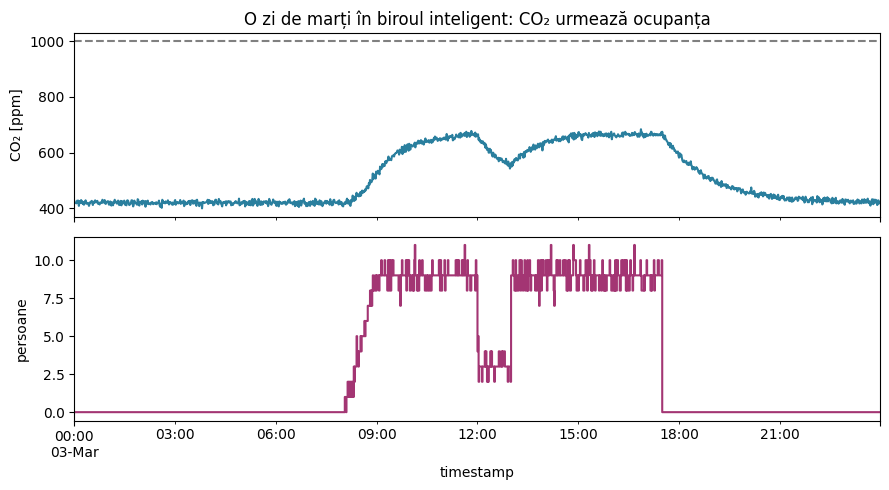

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("smart_office_dataset.csv", parse_dates=["timestamp"], index_col="timestamp")
print(df.shape)
print(df["co2_ppm"].describe().round(1))

day = df.loc["2026-03-03"]
fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
day["co2_ppm"].plot(ax=ax[0], color="#2A7F9E"); ax[0].set_ylabel("CO₂ [ppm]"); ax[0].axhline(1000, ls="--", c="grey")
day["occupancy"].plot(ax=ax[1], color="#A33573", drawstyle="steps-post"); ax[1].set_ylabel("persoane")
ax[0].set_title("O zi de marți în biroul inteligent: CO₂ urmează ocupanța"); plt.tight_layout(); plt.show()

## 11. Mini-proiect: raportul privind calitatea aerului din birou
Punem totul cap la cap: **fișier → buclă → funcție → clasă → raport**.

In [23]:
def load_co2(path):
    """Returnează o listă de perechi (timestamp, co2), sărind peste valorile lipsă."""
    out = []
    with open(path, newline="") as f:
        for row in csv.DictReader(f):
            try:
                out.append((row["timestamp"], float(row["co2_ppm"])))
            except ValueError:
                continue
    return out

def classify(value):
    return "bun" if value < 600 else "acceptabil" if value < 1000 else "slab"

data = load_co2("smart_office_dataset.csv")
sensor = Co2Sensor("co2-lab204")
rejected = [ts for ts, v in data if not sensor.add(v)]

levels = Counter(classify(v) for v in sensor.readings)
total = sum(levels.values())

print(sensor)
print(f"respinse ca imposibile: {len(rejected)}")
for level in ("bun", "acceptabil", "slab"):
    share = levels[level] / total
    print(f"{level:>10}: {levels[level]:5d} măsurători  ({share:6.1%})  " + "█" * int(share * 40))
worst = max(sensor.readings)
print("cea mai mare măsurătoare:", worst, "ppm")

Sensor('co2-lab204', 10047 măsurători, unit=ppm)
respinse ca imposibile: 2
       bun:  7496 măsurători  ( 74.6%)  █████████████████████████████
acceptabil:  2547 măsurători  ( 25.4%)  ██████████
      slab:     4 măsurători  (  0.0%)  
cea mai mare măsurătoare: 2400.0 ppm


🔎 **Priviți din nou linia „slab".** Doar 4 măsurători din ~10 000 depășesc 1000 ppm și sunt *toate* între 2100 și 2400 ppm, în timp ce următoarea cea mai mare valoare este de doar 746 ppm. Patru vârfuri izolate, de trei ori mai mari decât orice altceva, într-un birou care nu depășește niciodată ~700 ppm, arată ca **defecțiuni ale senzorului, nu ca aer prost**. Un raport care spune „biroul a avut 4 măsurători cu aer slab" ar induce în eroare. A învăța să *puneți la îndoială* astfel de numere este subiectul cursurilor de înțelegerea datelor (Data Understanding).

## 12. Recapitulare și fișă rezumat

| subiect | rețineți |
|---|---|
| tipuri | totul este un obiect; tipare dinamică, dar puternică; comparați numerele float cu `math.isclose` |
| containere | `list` `tuple` `set` `dict` (cu ordinea inserării din 3.7); secționare (slicing) `a[start:stop:step]`; comprehensiuni |
| șiruri | folosiți f-string: `f"{x:.2f}"` |
| controlul fluxului | `range` exclude capătul; `break` / `continue` / `for … else` |
| funcții | docstring, valori implicite, argumente cu nume, valori multiple returnate, `lambda` |
| clase | `__init__`, `self`, moștenire, `__repr__`, `@dataclass` |
| erori | `try / except EroareSpecifică`; a prinde o eroare ≠ a valida datele |
| fișiere | `with open(...)`, `pathlib`, `csv`, `json` |
| unelte | mediu virtual, `%pip install`, Colab / VS Code / JupyterLab |

**Lecturi suplimentare:** tutorialul Python https://docs.python.org/3/tutorial/ · PEP 8 https://peps.python.org/pep-0008/ · tutorialul Python de la GeeksforGeeks https://www.geeksforgeeks.org/python/python-programming-language-tutorial/

➡️ Urmează: deschideți **`Lab1_Exercitii.ipynb`**.